In [1]:
# Isabella Alvarez
# Project 
# November 12, 2026

In [2]:
import numpy as np              # load numerical module
import astropy.io.fits as fits  # load FITS module
import os
import matplotlib.pyplot as plt

In [3]:
print("Problem 3: ")

# Defining variables

# Directory containing the Transit FITS files
data_dir = "transit_data/"
fext = ".fits"

# Identify science files
files = sorted(os.listdir(data_dir))

bcd_files = []

for file in files:
    if file.endswith("_bcd.fits"):
        bcd_files.append(file)

# Number of science files
nfiles = len(bcd_files)

# Number of frames per subarray 
nframes = 64

# Subarray set parameters
start_set = 187
end_set = 686

# Number of sets to read (inclusive)
num_sets  = end_set - start_set + 1

# Frame parameter array column indices 
TIME      = 0 
FRAME_NUM = 1
BKG = 2

# Number of coloumns in frame parameters 
num_params = 3

# Enable or disable frame inspection
inspect_frames = False

# Print statements
print(f"Data Directory: {data_dir}")
print(f"FITS extension: {fext}")
print(f"Number of science files: {nfiles}")
print(f"First science file: {bcd_files[0]}")
print(f"Last science file: {bcd_files[-1]}")

Problem 3: 
Data Directory: transit_data/
FITS extension: .fits
Number of science files: 600
First science file: SPITZER_I4_20674048_0100_0000_2_bcd.fits
Last science file: SPITZER_I4_20674048_0699_0000_2_bcd.fits


In [4]:
print("Problem 4: Creating function")

def read_transit_data (data_dir, bcd_files, start_set, num_sets):
    """ 
    Read FITS subarray sets and extract metadata into pre-allocated arrays.

    Parameters:
    ----------
    data_dir: str
        Directory containing the FITS files.
    bcd_files: list
        Sorted list of science filenames. 
    start_set: numpy integer 
        Starting subarray set number.
    num_sets: numpy integer 
         Number of subarrays to process.

    Returns: 
    --------
    data_cube: numpy_like array 
        A 3D array of the shape containing the combined science data.
    frame_params: numpy_like array 
        A 2D array of the shape stroing per-frame metadata.
    """
    # Question 4a: Reading first data block
    filename     = os.path.join(data_dir, bcd_files[0])
    data, header = fits.getdata(filename, header = True)
    
    # Determine dimesnions
    nframes, ny, nx = data.shape
    
    # Print statements
    print(f"Number of frames per set: {nframes}")
    print(f"Image dimensions: {ny} x {nx}")
    print(f"First data cube shape: {data.shape}")
    
    # Question 4b: Pre-allocate Arrays 
    
    # Total number of observational frames 
    total_frames = nframes * num_sets
    
    # Creating the 3D data cube
    data_cube = np.zeros ((total_frames, ny, nx), dtype = np.float64)
    
    # Creating the 2D frame parameter array 
    frame_params = np.zeros((total_frames, num_params), dtype = np.float64)
    
    # Print array shapes 
    print(f"Data cube shape: {data_cube.shape}")
    print(f"Frame Parameter array shape: {frame_params.shape}")
    
    # Question 4c(i-ii): Read and Store Data

    # Select files starting at the requested set number 
    selected_files = []

    for file in bcd_files:
        # Extract the set number from the filename 
        set_number = int(file.split("_")[3])

        # Only include sets in the requested range
        if start_set <= set_number < start_set + num_sets:
            selected_files.append(file)
   
    # Verify the selected files
    if len(selected_files) != num_sets:
        raise ValueError("Missing or extra FITS files in selected range.")

    # Print Statements
    print("First selected file:", selected_files[0])
    print("Last selected file:", selected_files[-1])
    print("Number of selected files:", len(selected_files))


    # Loop through each subarray set
    for i, file in enumerate(selected_files):
        
        # Construct the filename
        filename = os.path.join(data_dir, file)
        
        # Read the science data and header
        data, header = fits.getdata(filename, header=True)
        
        # Determine were the 64 frames belong
        first_frame = i * nframes
        last_frame = first_frame + nframes
        
        # Insert the images into the data cube
        data_cube[first_frame : last_frame, :, :] = data
        
        # Question 4c(iii): Frame Parameters

        # Read FITS header
        start_time = header ["MJD_OBS"]
        exptime    = header ["EXPTIME"]
        framtime   = header ["FRAMTIME"]
        
        # Frame indices within current set
        frame_indices = np.arange(nframes)
        
        # Calculating midpoint times in MJD
        frame_times = start_time + ((exptime / 2) + frame_indices * framtime
                                / 86400.0)
        
        # Store observation times 
        frame_params[ first_frame : last_frame, TIME] = frame_times 
        
        # Store sequential frame numbers 
        frame_params[ first_frame : last_frame, FRAME_NUM ] = np.arange (first_frame, last_frame)

    return data_cube, frame_params


Problem 4: Creating function


In [5]:
print("Question 5:")
data_cube, frame_params = read_transit_data(data_dir, bcd_files, start_set, num_sets)

# Check resulting shapes
print("Data cube shape:", data_cube.shape)
print("Frame parameter shape:", frame_params.shape)

# Check the final five frames 
for i in range(5):
    frame_index = len(data_cube) - 5 + i
    print(f"Frame {frame_index}: {np.mean(data_cube[frame_index])}")

# Optional Frame Inspection 
if inspect_frames:

    # Frames near beginning, middle, and end
    check_frames = [0, 16000, 31999]

    for i in check_frames:

        plt.figure(figsize=(5, 5))
        plt.imshow(data_cube[i], origin="lower",
                   cmap="gray")
        plt.colorbar(label="Pixel value")

        plt.title(f"Frame {i}")
        plt.xlabel("X pixel")
        plt.ylabel("Y pixel")
        plt.show()

# Optional rapid inspection 
if inspect_frames:

    # Select 12 evenly spaced frames
    sample_frames = np.linspace(0, len(data_cube) - 1, 12, dtype = int )

    fig, axes = plt.subplots(3, 4, figsize = (12, 9))

    for ax, i in zip(axes.flat, sample_frames):

        ax.imshow(data_cube[i], origin = "lower", cmap = "gray")
        ax.set_title(f"Frame {i}")

    plt.tight_layout()
    plt.show()

Question 5:
Number of frames per set: 64
Image dimensions: 32 x 32
First data cube shape: (64, 32, 32)
Data cube shape: (32000, 32, 32)
Frame Parameter array shape: (32000, 3)
First selected file: SPITZER_I4_20674048_0187_0000_2_bcd.fits
Last selected file: SPITZER_I4_20674048_0686_0000_2_bcd.fits
Number of selected files: 500
Data cube shape: (32000, 32, 32)
Frame parameter shape: (32000, 3)
Frame 31995: 16.02701680039172
Frame 31996: 15.819258372104741
Frame 31997: 15.87025531814379
Frame 31998: 16.039337915124634
Frame 31999: 15.979136541231128


In [6]:
print("Question 6: Boolean Mask")

mask = np.ones(data_cube.shape, dtype = bool) 

# Print the shape
print("Data cube shape:", data_cube.shape)
print("Mask shape:", mask.shape)

# Check mask values
print("All pixels initially good:", np.all(mask))

Question 6: Boolean Mask
Data cube shape: (32000, 32, 32)
Mask shape: (32000, 32, 32)
All pixels initially good: True


Question 7:


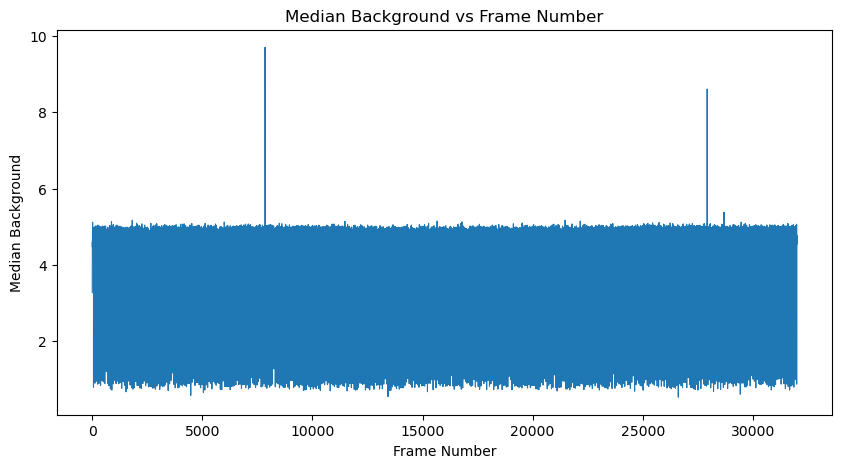

Median background shape: (32000,)
First five background values: [3.26993966 4.45008087 4.257164   4.45727777 4.57183051]
First five corrected medians:
[0. 0. 0. 0. 0.]


In [7]:
print("Question 7:")

# Calculating the median background for each frame 
median_bkg = np.median(data_cube, axis = (1,2))

# Storing values in the frame parameter array 
frame_params[:, BKG] = median_bkg

# Subtracting median background from each frame 
data_cube -= median_bkg[:, np.newaxis, np.newaxis]

# Ensure flagged pixels remain zero 
data_cube[~mask] = 0

# Plot median background vs frame number 

plt.figure(figsize = (10,5))
plt.plot(frame_params[:, FRAME_NUM], frame_params[:, BKG], linewidth = 0.8)

   # Labels
plt.xlabel("Frame Number")
plt.ylabel("Median Background")
plt.title("Median Background vs Frame Number")

plt.savefig("project_ialvarez27_problem7_median_background.png", dpi = 300, bbox_inches = "tight")
plt.show()

# Print results
print("Median background shape:", median_bkg.shape)
print("First five background values:", median_bkg[:5])

# Check median after background subtraction
corrected_medians = np.median(data_cube, axis=(1, 2))

print("First five corrected medians:")
print(corrected_medians[:5])

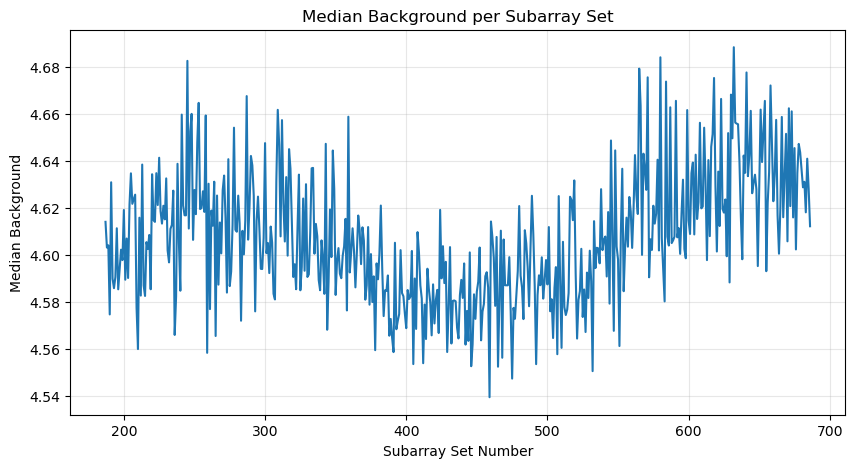

In [8]:
# Calculate median background for each subarray set
set_background = frame_params[:, BKG].reshape(
    num_sets, nframes
)

median_per_set = np.median(set_background, axis=1)

# Plot background by subarray set
plt.figure(figsize=(10, 5))

plt.plot(np.arange(start_set, start_set + num_sets),
         median_per_set)

plt.xlabel("Subarray Set Number")
plt.ylabel("Median Background")
plt.title("Median Background per Subarray Set")
plt.grid(alpha=0.3)
plt.show()


In [9]:
print("Question 8: Sigma-Rejection Routine")

def sigrej(data, axis = 0, nsigma = 5):
    """
    Performs two iterations of sigma rejection.

    Parameters:
    ----------
    data   : numerical array_like 
          An array containing the measurements.
    axis   : numpy integer 
          Axis along which sigma rejection is performed.
    nsigma :  float
          Number of standard deviations for rejection. 
    Returns:
    --------
    good: numerical array_like of bool
        Boolean array with True for good values and False
        for rejected values.
    """
    # Initial consideration: all finite values good
    good = np.isfinite(data)

    # Perform two iterations of sigma rejection
    for iteration in range(2):

        # Exclude previously rejected values 
        valid_data = np.where(good, data, np.nan)

        # Calculate median of good 
        median = np.nanmedian(valid_data, axis = axis, keepdims = True)

        # Calculate deviations from the median
        deviations = data - median

        # Calculate squared deviations of good values 
        squard_diff = np.where(good, deviations**2, 0)

        # Count the remaining good
        n_good = np.sum(good, axis = axis, keepdims = True)

        # Standard deviation from the median 
        sigma = np.sqrt(np.sum(squard_diff, axis = axis, keepdims = True) 
                        / np.maximum(n_good, 1))

        # Identify measurements within 5 sigma
        within_limit = (np.abs(deviations) <= nsigma * sigma)

        # Update Boolean mask 
        good = good & within_limit
    return good

Question 8: Sigma-Rejection Routine


Question 9
Sigma Rejection shape: (500, 64, 32, 32)
Bad Pixels: 2658
Total rejected pixels: 2658
Maximum rejected pixels in one frame: 257


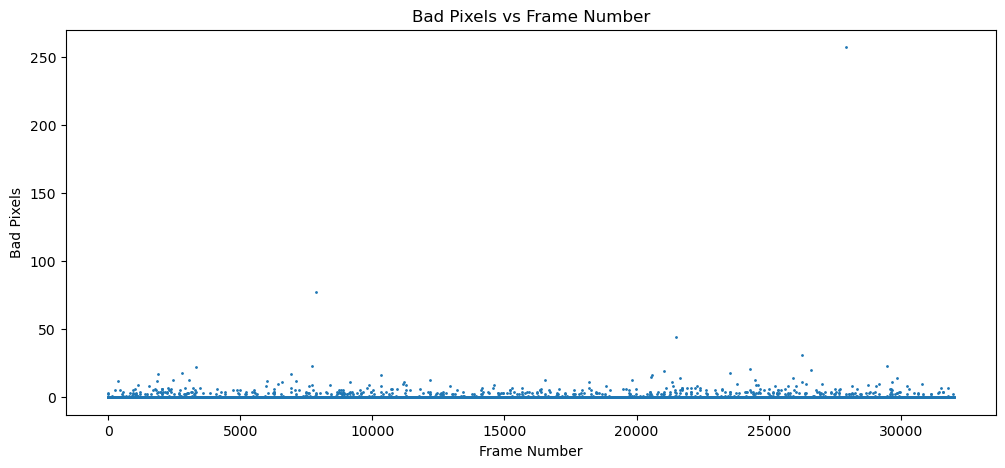

In [21]:
print("Question 9")

# Obtain image dimensions 
ny, nx = data_cube.shape[1: ]

# Reshaping data for sigma rejection 
data_4d = data_cube.reshape(num_sets, nframes, ny, nx)

# Applying sigma rejection to the 64 exposures in each set
good_4d = sigrej(data_4d, axis = 1, nsigma = 5)

# Check the results 
print(f"Sigma Rejection shape: {good_4d.shape}")
print(f"Bad Pixels: {np.sum(~good_4d)}")

# Reshape sigma rejection results to match the original cube 
good_mask = good_4d.reshape(data_cube.shape)

# Update the original Boolean mask 
mask &= good_mask 

# Count rejected pixels in each frame 
bad_per_frame = np.sum(~mask, axis = (1,2))
print("Total rejected pixels:", np.sum(bad_per_frame))
print("Maximum rejected pixels in one frame:", np.max(bad_per_frame))

# Plot number of rejected pixels per frame 
plt.figure(figsize = (12,5))
plt.plot(frame_params[:, FRAME_NUM], bad_per_frame, '.', markersize = 2)

# Labels
plt.xlabel("Frame Number")
plt.ylabel("Bad Pixels")
plt.title("Bad Pixels vs Frame Number")
plt.savefig("project_ialvarez27_problem9_bad_pixels_graph.png", dpi = 300, bbox_inches = "tight")

plt.show()

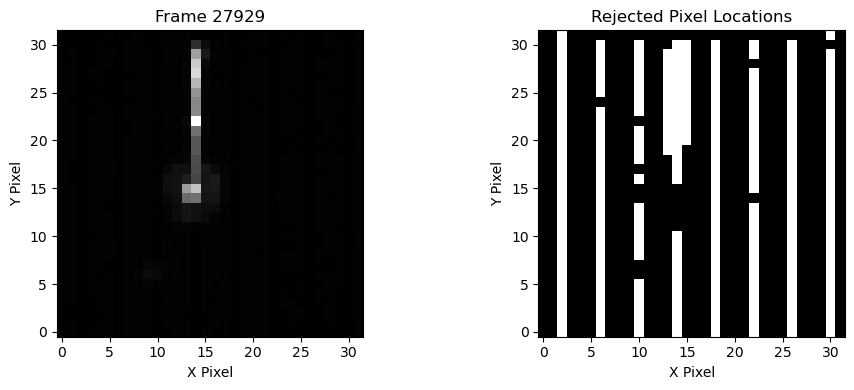

In [22]:
# Further investigation 

worst_frame = np.argmax(bad_per_frame)

fig, ax = plt.subplots(1, 2, figsize = (10, 4))

# Display the observational frame
ax[0].imshow(data_cube[worst_frame], origin  = 'lower',
             cmap = 'gray')
ax[0].set_title("Frame 27929")
ax[0].set_xlabel("X Pixel")
ax[0].set_ylabel("Y Pixel")

# Display rejected pixels
ax[1].imshow(~mask [worst_frame], origin = 'lower',
             cmap = 'gray', vmin = 0, vmax = 1)
ax[1].set_title("Rejected Pixel Locations")
ax[1].set_xlabel("X Pixel")
ax[1].set_ylabel("Y Pixel")

plt.tight_layout()
plt.show()


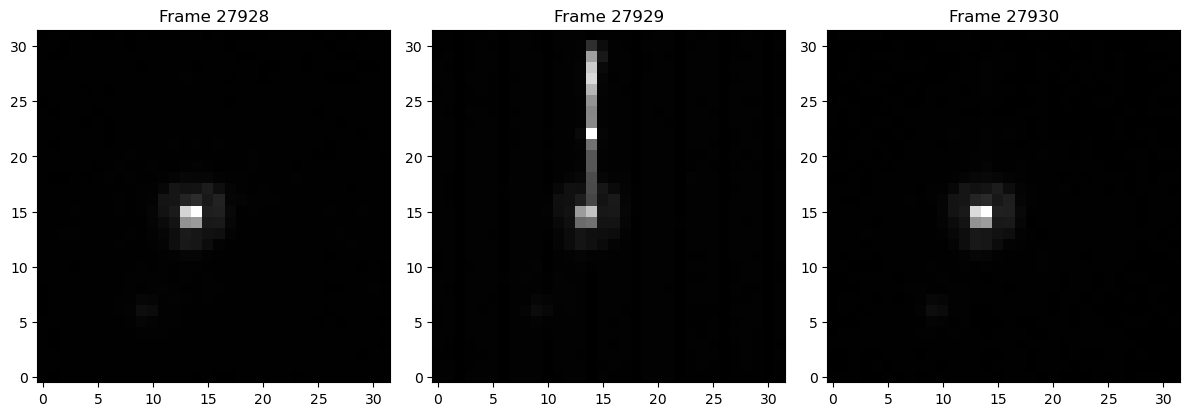

In [23]:
# Compared with neighboring frames

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

for i, frame in enumerate([27928, 27929, 27930]):
    ax[i].imshow(data_cube[frame], origin='lower', cmap='gray')
    ax[i].set_title(f"Frame {frame}")

plt.tight_layout()
plt.show()